**TD 1 - Smart Machining - Exercise 2**

This exercise will allow you to predict cutting forces and cutting power in axial drilling.

In [1]:
import numpy as np
import math

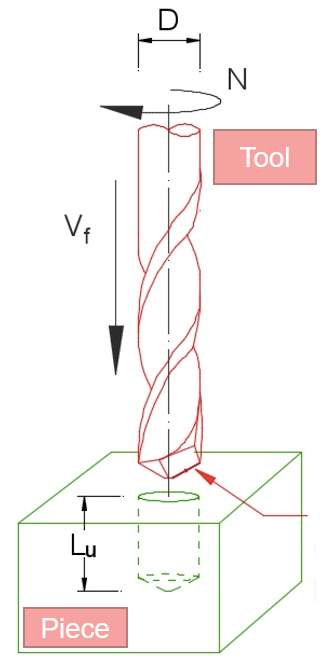

1) The input parameters for the drilling processes are :


*   Tool Diameter is 6 mm
*   The tool point angle is $120^o$
*   The drilling depth is 8 mm
*   The feed per revolution is 0,1 mm/rev
*   The cutting speed for Aluminum is 200 mm/min
*   The estimated specific cutting force for this tool and material is 2000 MPa





In [2]:
D = 6   #(mm)
alpha = 30 #(deg) <- 90° - 120°/2
f = 0.1 #(mm/rev)
Vc = 200    #(mm/min)
Kc = 2000   #(MPa)
tooth = 2
depth = 8   #(mm)

2) Calculate the depth of cut (mm), the spindle speed (in rpm), the feed velocity (mm/min)

In [3]:
ap = D/2  #(mm)
print("Depth of cut (mm): ", round(ap,2))

N = Vc/(np.pi*D)   #(rpm)
print("Spindle speed (rpm): ", round(N,2))

Vf = tooth*f*N  #(mm/min)
print("Feed velocity (mm/min): ", round(Vf,2))

Depth of cut (mm):  3.0
Spindle speed (rpm):  10.61
Feed velocity (mm/min):  2.12


3) Calculate the area of cut when the tool is in contact to the workpiece and the cutting force for each cutting edge (there are two !)

$F_c^{(1)} = K_c a_p f_t$

In [4]:
Ac = ap*f #(mm2) NOTe: equal to ap/math.cos(alpha*np.pi/180) * f*math.cos(alpha*np.pi/180)
print("Area of cut (mm2/rev): ", round(Ac,2))

Fc1 = Kc * Ac  #(N)
print("Cutting force per single edge(N): ", round(Fc1,2))

Area of cut (mm2/rev):  0.3
Cutting force per single edge(N):  600.0


Notice that the total cutting force $F_{c_{tot}} = F_{c1} - F_{c1} = 0$

4) Calculate the machining time for the hole and the volume of chip

In [ ]:
tm = depth/Vf * 60   #(s)
print("Machining time (s): ", round(tm,2))

b = ap/math.cos(alpha*np.pi/180)    #(mm)
c = math.sqrt(b*b - ap*ap)

Vol = np.pi*c*D*D/(4*3) + np.pi*(depth-c)*D*D/4 #(mm3)
print("Chip Volume (mm3): ", round(Vol,2))

Machining time (s):  226.19
Chip Volume (mm3):  193.55


5) Plot a curve of the cutting force for the complete time of cut considering that the tool begin from 100 mm distance to the workpiece and the tool velocity when it is not cutting is 500 mm/min.

In [7]:
# No-load pass
L1 = 100    #(mm)
Vf1 = 500   #(mm/min)
t1 = L1/500 * 60    #(s)

t_tot = tm + t1 #(s)

time = np.arange(0, t_tot, 1)    # time-step = 1s -> data-mesh
force = np.where(time > t1, Fc1, 0)

M = np.column_stack((time, force))

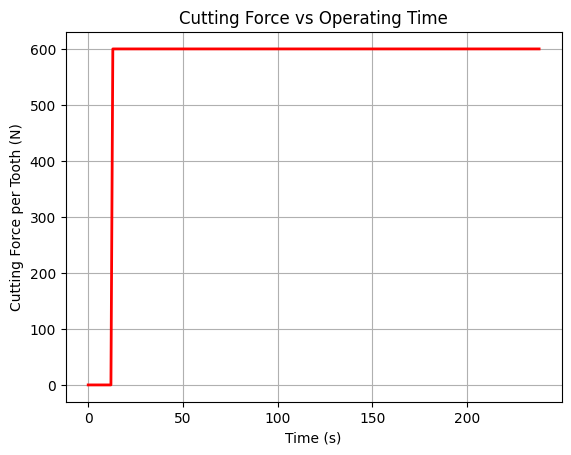

In [8]:
import matplotlib.pyplot as plt

plt.plot(M[:,0], M[:,1], color="red", linewidth=2)
plt.xlabel("Time (s)")
plt.ylabel("Cutting Force per Tooth (N)")
plt.grid(True)
plt.title("Cutting Force vs Operating Time")
plt.show()

6) Now calculate the same in cutting power.

In [11]:
Pc1 = force*Vc/2 *1000/60
Pc_tot = Pc1 * 2
M_new = np.column_stack((M, Pc1, Pc_tot))

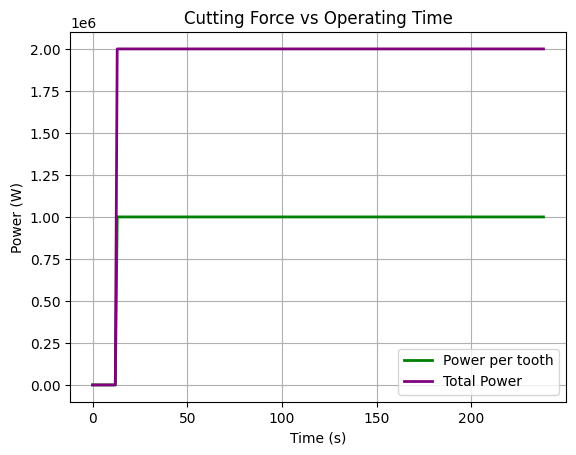

In [20]:
plt.plot(M_new[:,0], M_new[:,2], color="green", linewidth=2, label = "Power per tooth")
plt.plot(M_new[:,0], M_new[:,3], color="purple", linewidth=2, label = "Total Power")
plt.xlabel("Time (s)")
plt.ylabel("Power (W)")
plt.grid(True)
plt.title("Cutting Force vs Operating Time")
plt.legend()
plt.show()